In [9]:
from google.colab import drive
import cv2, glob, os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [1]:
drive.mount('/content/drive')
folder = '/content/drive/MyDrive/CV/CV_Act_7/Photos/Originals'

paths = sorted(p for p in glob.glob(os.path.join(folder, '*'))
               if p.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')))

images = {os.path.basename(p): cv2.imread(p) for p in paths}
grays = {name: cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for name, img in images.items()}

for name, img in images.items():
    print(name, img.shape)

Mounted at /content/drive
lois.jpg (720, 720, 3)
old_man.jpg (1280, 853, 3)
son.jpg (679, 452, 3)
winston.jpg (825, 640, 3)


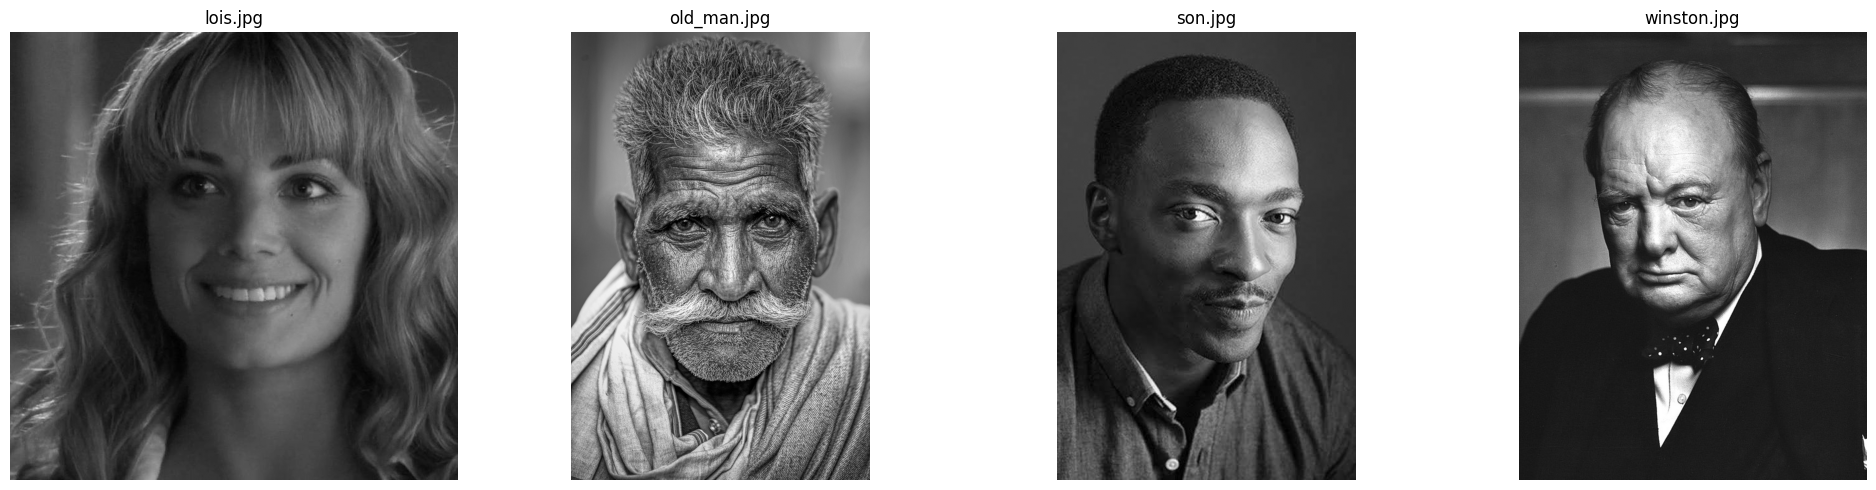

In [2]:

fig, ax = plt.subplots(1, len(grays), figsize=(5 * len(grays), 5))
for a, (name, gray) in zip(ax, grays.items()):
    a.imshow(gray, cmap='gray')
    a.set_title(name)
    a.axis('off')
plt.tight_layout()
plt.show()

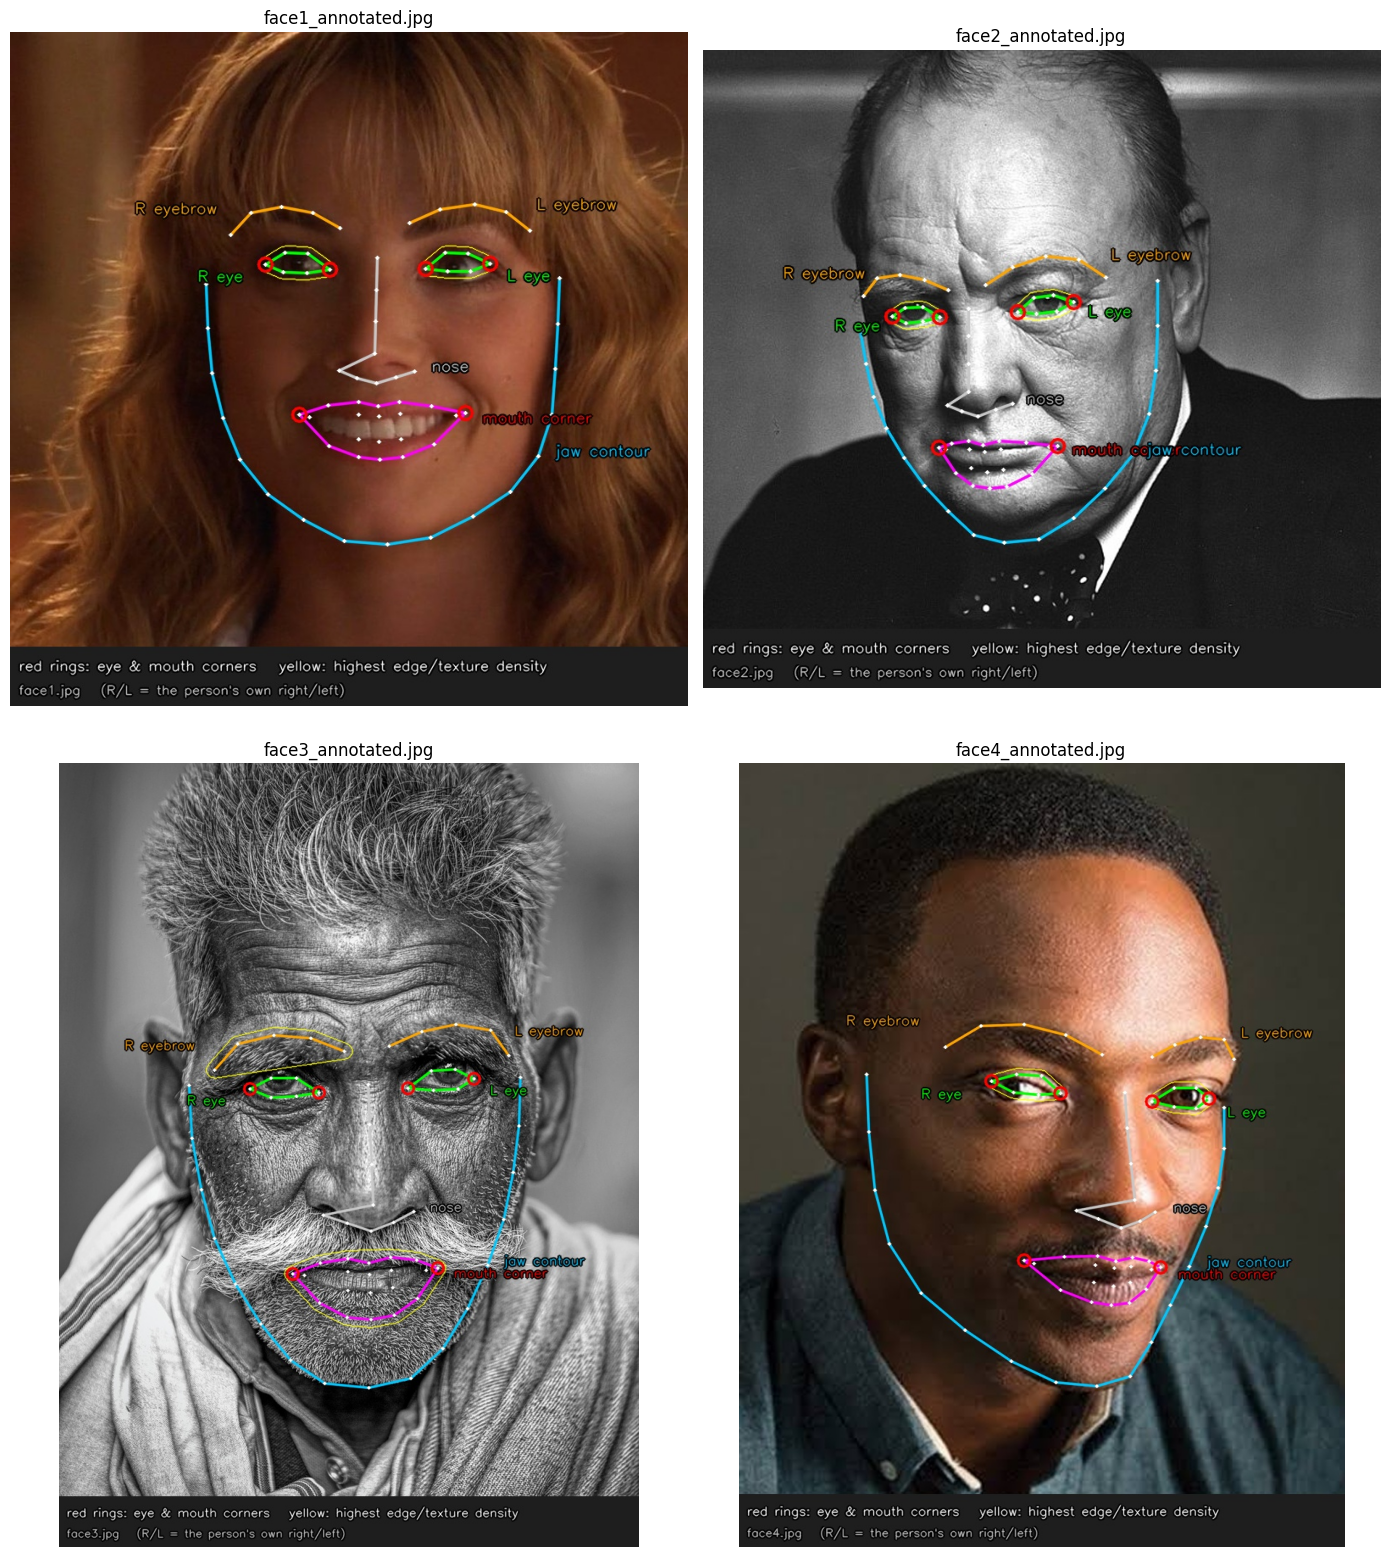

In [20]:
annotated_folder = '/content/drive/MyDrive/CV/CV_Act_7/Photos/Annotated'

#annotations were done with a cv2 model

ann_paths = sorted(p for p in glob.glob(os.path.join(annotated_folder, '*'))
                   if p.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')))

fig, ax = plt.subplots(2, 2, figsize=(14, 16))
for a, p in zip(ax.flat, ann_paths):
    a.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
    a.set_title(os.path.basename(p))
for a in ax.flat:
    a.axis('off')
plt.tight_layout()
plt.show()

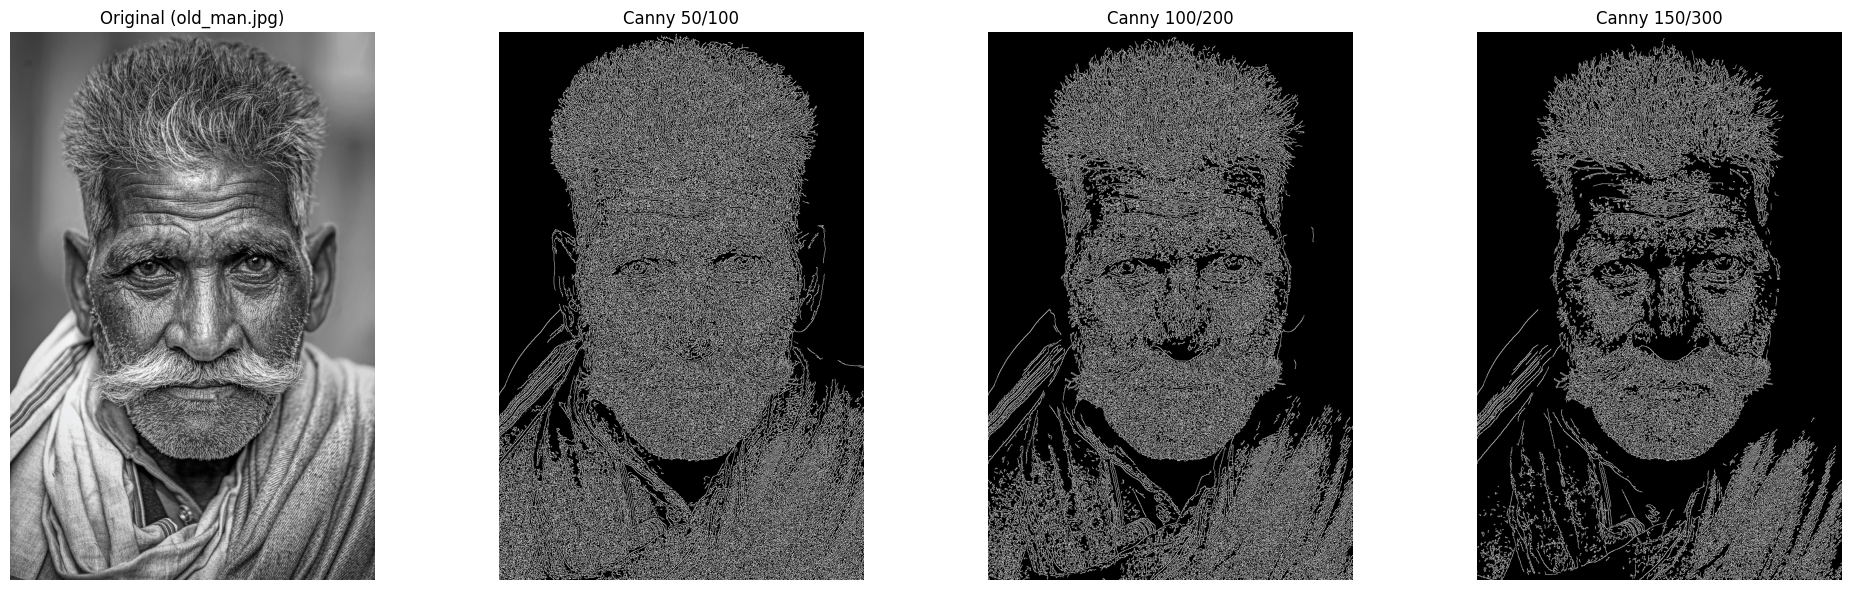

In [8]:
name = list(images)[1] #picked out the old man since it looks to have the most apparent edges
img, gray = images[name], grays[name]

thresholds = [(50, 100), (100, 200), (150, 300)]   # loose, default, strict
fig, ax = plt.subplots(1, 1 + len(thresholds), figsize=(20, 6))

ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
ax[0].set_title(f'Original ({name})')

for i, (lo, hi) in enumerate(thresholds):

  #call canny over the different thresholds
  #gauss blur applied for clearer results
    cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(gray, lo, hi)
    ax[i + 1].imshow(edges, cmap='gray')
    ax[i + 1].set_title(f'Canny {lo}/{hi}')

for a in ax: a.axis('off')
plt.tight_layout()
plt.show()

In [10]:
def harris(bgr, ratio=0.01):
    g = np.float32(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY))
    r = cv2.dilate(cv2.cornerHarris(g, blockSize=2, ksize=3, k=0.04), np.ones((5, 5)))
    view = bgr.copy()
    view[r > ratio * r.max()] = [0, 0, 255] # mark corners red
    return view, int((r > ratio * r.max()).sum())


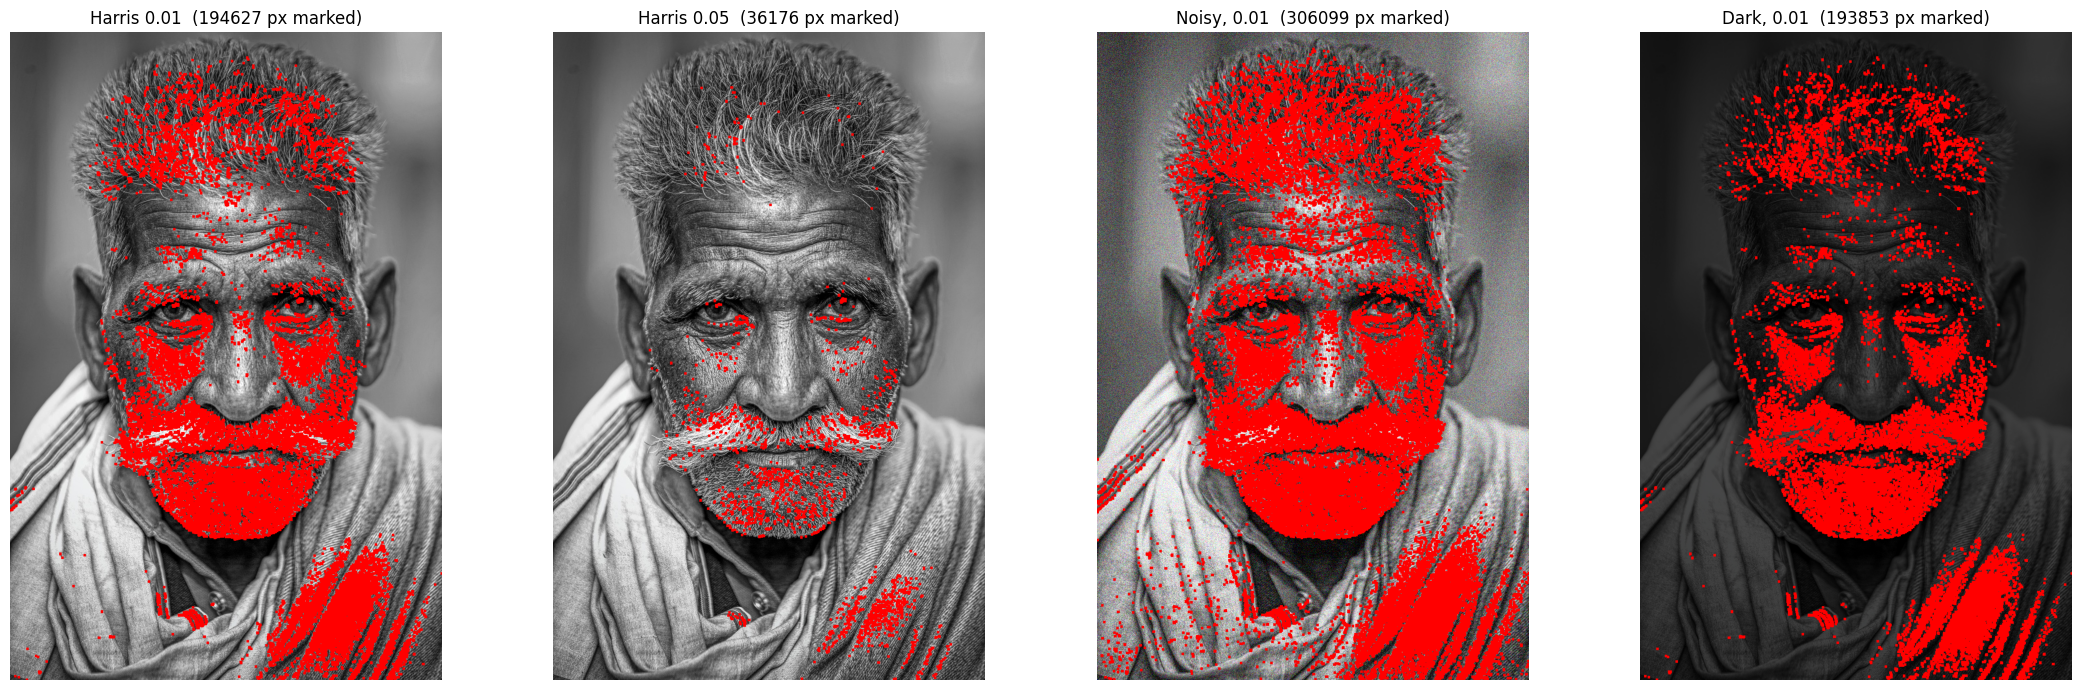

In [11]:
name = list(images)[1] # same image as Task 2
img = images[name]

noisy = np.clip(img + np.random.normal(0, 25, img.shape), 0, 255).astype(np.uint8)   # add noise
dark = (img * 0.3).astype(np.uint8)                                                  # poorly lit

tests = [('Harris 0.01', img, 0.01), ('Harris 0.05', img, 0.05),
         ('Noisy, 0.01', noisy, 0.01), ('Dark, 0.01', dark, 0.01)]

fig, ax = plt.subplots(1, len(tests), figsize=(22, 7))
for a, (title, src, ratio) in zip(ax, tests):
    view, n = harris(src, ratio)
    a.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB))
    a.set_title(f'{title}  ({n} px marked)')
    a.axis('off')
plt.tight_layout()
plt.show()

In [14]:
names = list(images)
print(names)

#manually placed face box, OpenCV5 removed the Haar face detector :(
FACE_BOX = {
    'lois.jpg':    (0.23, 0.11, 0.85, 0.73),
    'old_man.jpg': (0.15, 0.25, 0.89, 0.74),
    'son.jpg':     (0.29, 0.25, 0.92, 0.67),
    'winston.jpg': (0.16, 0.24, 0.64, 0.60),
}
pair = [names[0], names[3]]


['lois.jpg', 'old_man.jpg', 'son.jpg', 'winston.jpg']


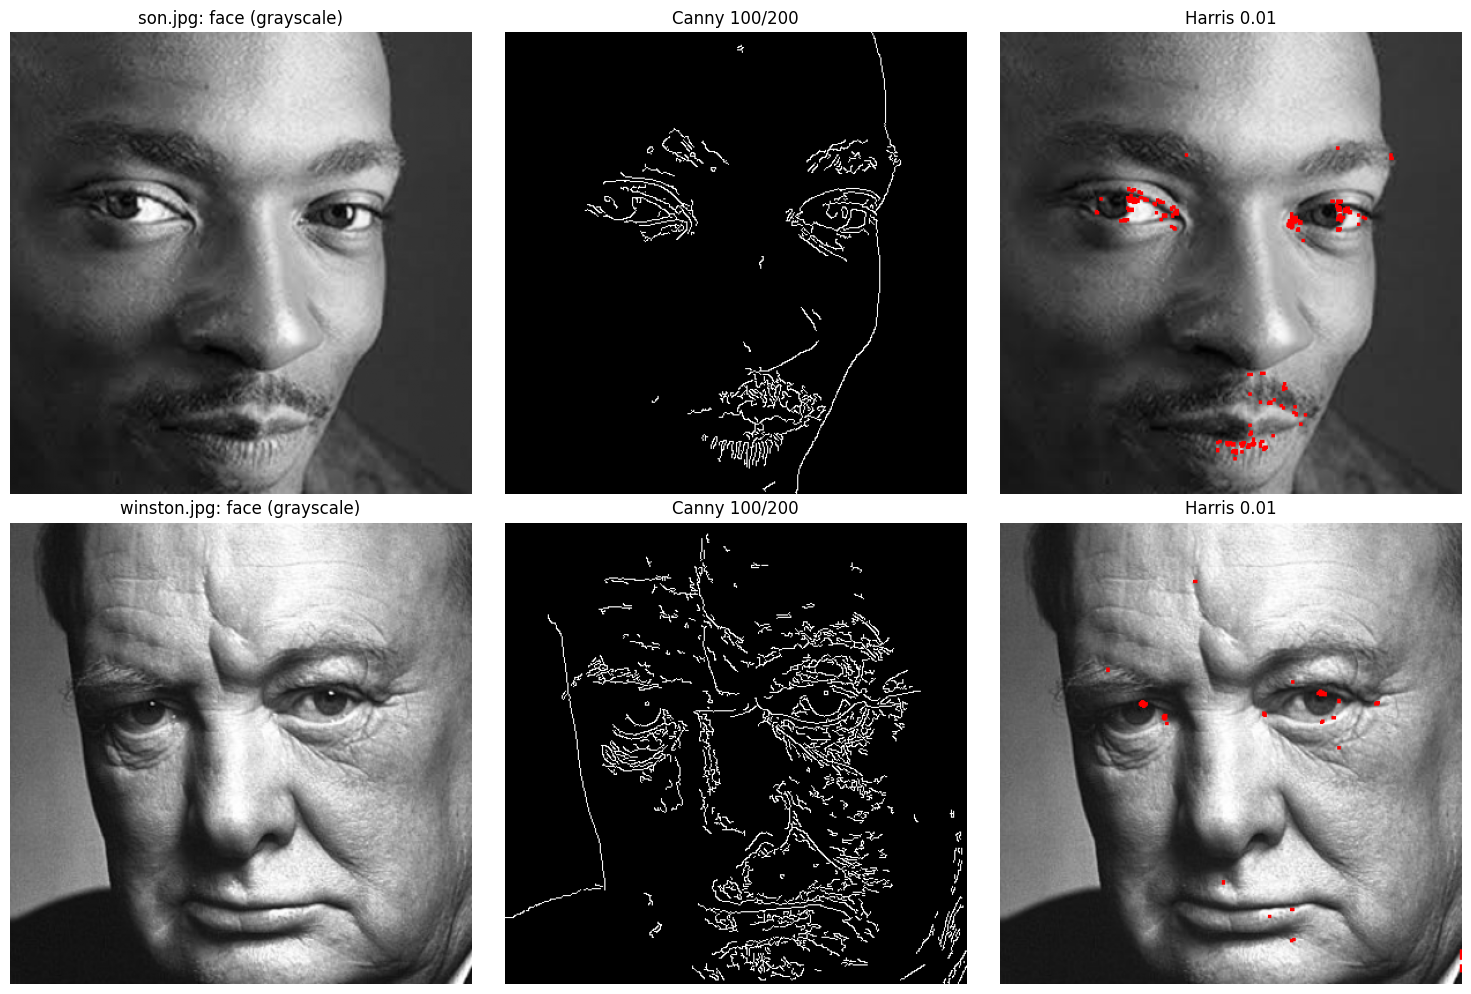

image,son.jpg,winston.jpg
mean brightness (0-255),89.40,127.10
contrast (std),59.30,65.20
edge pixels (%),2.48,6.24
corner pixels (%),0.16,0.05
left half brightness,63.30,97.00
right half brightness,115.50,157.20


In [18]:
pair = [names[2], names[3]]

rows, fig, ax = [], *plt.subplots(2, 3, figsize=(15, 10))
for r, name in enumerate(pair):
    x0, y0, x1, y1 = FACE_BOX[name]
    g = grays[name]; H, W = g.shape
    face = cv2.resize(g[int(y0*H):int(y1*H), int(x0*W):int(x1*W)], (400, 400)) # same size for a fair comparison

    edges = cv2.Canny(face, 100, 200)
    R = cv2.cornerHarris(np.float32(face), 2, 3, 0.04)
    corners = R > 0.01 * R.max()
    view = cv2.cvtColor(face, cv2.COLOR_GRAY2BGR)
    view[cv2.dilate(corners.astype(np.uint8), None) > 0] = [0, 0, 255]

    ax[r, 0].imshow(face, cmap='gray')
    ax[r, 0].set_title(f'{name}: face (grayscale)')
    ax[r, 1].imshow(edges, cmap='gray')
    ax[r, 1].set_title('Canny 100/200')
    ax[r, 2].imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB))
    ax[r, 2].set_title('Harris 0.01')

    left, right = face[:, :200], face[:, 200:]
    rows.append({'image': name,
                 'mean brightness (0-255)': round(face.mean(), 1),
                 'contrast (std)': round(face.std(), 1),
                 'edge pixels (%)': round((edges > 0).mean() * 100, 2),
                 'corner pixels (%)': round(corners.mean() * 100, 2),
                 'left half brightness': round(left.mean(), 1),
                 'right half brightness': round(right.mean(), 1)})

for a in ax.flat: a.axis('off')
plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index('image').T